# 14. Nematic liquid crystals

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 2–5

In a nematic liquid crystal, rod-like molecules flow like a liquid but point, on
average, in a common direction, the *director* $\mathbf n$. The director can be turned by
walls, by electric and magnetic fields and by flow, and every liquid-crystal display
works by turning it. Turning the director costs elastic energy, because neighbouring
regions prefer to be parallel, and it dissipates energy, because the molecules must
rotate through their neighbours.

These are again the two functions of the Onsager principle, now for an orientation
rather than a position. This chapter writes them for the simplest case, a twist cell,
where the director rotates in planes parallel to the walls and no fluid has to move.
A field turns the director only above a threshold, the Fréedericksz transition, which
has an exact solution in elliptic integrals; we use it to test a trial function with
one Fourier mode, which turns out to be exact at the threshold and to fail, in an
instructive way, at strong fields. The last part puts the director in a shear flow.
The dissipation function then couples the rotation of the director to the shear rate,
and Onsager's reciprocity relation (Chapter 2) is the Parodi relation between the
viscosities of a nematic. The director either aligns at a fixed angle to the flow or
tumbles, and in a cell it forms thin boundary layers at the walls.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq
from scipy.special import j1

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 14.1 The two functions of a twist cell

A nematic layer of thickness $d$ lies between two plates at $z = 0$ and $z = d$, which
anchor the director along $x$. A field $\mathbf F$ (electric or magnetic) is applied along $y$,
in the plane of the layer. If the molecules prefer to lie along the field, they turn
towards $y$, rotating in planes parallel to the plates: $\mathbf n = (\cos\phi, \sin\phi, 0)$ with
the twist angle $\phi(z,t)$, and $\phi = 0$ at both plates.

*Free energy.* The elastic free energy of a distorted nematic is that of Frank
(1958), with three constants for splay, twist and bend. Here only twist occurs, with
the constant $K_2$. The field adds $-\tfrac12\chi F^2(\mathbf n\cdot\hat{\mathbf y})^2$, with $\chi F^2 = \varepsilon_0\Delta\varepsilon E^2$ for an
electric field (dielectric anisotropy $\Delta\varepsilon > 0$) or $\mu_0\Delta\chi H^2$ for a magnetic one. Per unit
area of the cell,

$$ A = \int_0^d\Big[\frac{K_2}{2}\Big(\frac{\partial\phi}{\partial z}\Big)^2 - \frac{\chi F^2}{2}\sin^2\phi\Big]\,dz . \tag{14.1} $$

*Dissipation.* When the director rotates, the molecules turn against the friction of
their neighbours, with the rotational viscosity $\gamma_1$. A pure twist moves no fluid, so
this is the only dissipation:

$$ \Phi = \frac{\gamma_1}{2}\int_0^d\Big(\frac{\partial\phi}{\partial t}\Big)^2\,dz . \tag{14.2} $$

*Minimise.* $R = \Phi + \dot A$ gives the torque balance

$$ \gamma_1\frac{\partial\phi}{\partial t} = K_2\frac{\partial^2\phi}{\partial z^2} + \chi F^2\sin\phi\cos\phi . \tag{14.3} $$

Elastic torque and field torque are balanced by viscous torque. The function
`on.director_fd` solves equations of this form by finite differences.

In [2]:
z = sp.symbols("z")
phi = sp.Function("phi")(z)                                          # the profile at one instant
K2, chiF2, gamma1, w = sp.symbols("K_2 chiF2 gamma_1 w")
density = K2 / 2 * sp.diff(phi, z) ** 2 - chiF2 / 2 * sp.sin(phi) ** 2
dA = sp.euler_equations(density, [phi], [z])[0].lhs                 # delta A / delta phi
R = gamma1 / 2 * w**2 + dA * w                                       # Rayleighian density, w = dphi/dt
print("gamma_1 dphi/dt =", sp.simplify(gamma1 * sp.solve(sp.diff(R, w), w)[0]))

gamma_1 dphi/dt = K_2*Derivative(phi(z), (z, 2)) + chiF2*sin(2*phi(z))/2


## 14.2 The Fréedericksz transition

*Threshold.* For a small twist, $\phi = a(t)\sin(\pi z/d)$ grows at the rate $(\chi F^2 - K_2\pi^2/d^2)/\gamma_1$. The
undistorted state is stable until the field reaches the threshold

$$ F_c = \frac{\pi}{d}\Big(\frac{K_2}{\chi}\Big)^{1/2} , \tag{14.4} $$

observed by Fréedericksz and Zolina (1933). The threshold does not depend on the
viscosity, and it falls as $1/d$: thin cells need strong fields.

*Units.* Lengths in $d$, times in $\tau_0 = \gamma_1d^2/\pi^2K_2$, field in units of $F_c$, $h = F/F_c$:

$$ \frac{\partial\phi}{\partial t} = \frac{1}{\pi^2}\frac{\partial^2\phi}{\partial z^2} + h^2\sin\phi\cos\phi . \tag{14.5} $$

*Switching times.* Small twists grow at the rate $h^2 - 1$ when the field is switched on,
and decay at the rate $1$ when it is switched off. In real units these are the
response times of Jakeman and Raynes (1972),

$$ \tau_{\rm on} = \frac{\gamma_1}{\chi F^2 - K_2\pi^2/d^2} , \qquad \tau_{\rm off} = \tau_0 = \frac{\gamma_1d^2}{\pi^2K_2} . \tag{14.6} $$

*The exact steady state.* Above the threshold Eq. (14.5) has a distorted steady state.
Multiplying it by $\phi'$ and integrating once gives $\phi'^2/\pi^2 = h^2(\sin^2\phi_m - \sin^2\phi)$, where $\phi_m$
is the twist at the mid-plane. Integrating again from the wall to the mid-plane,

$$ h = \frac{2}{\pi}\,\mathsf K(\sin\phi_m) , \tag{14.7} $$

where $\mathsf K(k) = \int_0^{\pi/2}d\psi/(1 - k^2\sin^2\psi)^{1/2}$ is the complete elliptic integral of the first
kind (`on.freedericksz_twist_angle` inverts it). Close to the threshold
$\mathsf K \approx \tfrac\pi2(1 + \tfrac14k^2)$, so $\phi_m \approx 2(h - 1)^{1/2}$: the twist grows continuously from zero, like the
order parameter at a second-order phase transition.

*Typical numbers.* With $K_2 \sim 3$ pN, $\gamma_1 \sim 0.1$ Pa s and $d = 5$ µm, orders of magnitude
typical of display materials, $\tau_0 = \gamma_1d^2/\pi^2K_2 \approx 80$ ms.

## 14.3 A one-mode trial function

Try the lowest mode, $\phi = a(t)\sin\pi z$. The friction of $a$ is $\tfrac12\gamma_1$ per unit length, and the
field term averages to a Bessel function, because $\int_0^1\sin(2a\sin\pi z)\sin\pi z\,dz = J_1(2a)$.
Minimising the Rayleighian gives

$$ \frac{da}{dt} = -a + h^2J_1(2a) . \tag{14.8} $$

For small $a$, $J_1(2a) \approx a - \tfrac12a^3$, which gives the exact growth rate and, in the steady
state, $a^2 \approx 4(h - 1)$: the same as the exact solution. The trial is exact at the
threshold. For strong fields it cannot be right: a sine profile has its maximum
slope at the walls, while the real twist rises steeply near the walls and is flat in
the middle, where the director has turned along the field. The cell below compares
the trial with one mode (Eq. 14.8) and with several odd modes, $\phi = \sum a_j\sin(j\pi z)$, with
the exact angle (14.7) and the finite-difference solution of Eq. (14.5).

In [3]:
def ritz_twist(h, n_modes, t_eval, a0=0.01, nz=800):
    """Odd sine modes, sum a_j sin(j pi z); returns the amplitudes and the profile on a grid."""
    zq = (np.arange(nz) + 0.5) / nz
    j = 2 * np.arange(n_modes) + 1
    S = np.sin(np.outer(j, np.pi * zq))
    def rhs(t, a):
        p = a @ S
        return -(j**2) * a + 2 * h * h * (S @ (np.sin(p) * np.cos(p))) / nz
    a_init = np.zeros(n_modes); a_init[0] = a0
    a = solve_ivp(rhs, (t_eval[0], t_eval[-1]), a_init, t_eval=t_eval, method="LSODA", rtol=1e-10, atol=1e-12).y.T
    return a, zq, S

def one_mode_steady(h):
    return brentq(lambda a: a - h * h * j1(2 * a), 1e-9, 1.9159) if h > 1 else 0.0

n = 399
zz = np.arange(1, n + 1) / (n + 1)
fields = np.array([1.02, 1.05, 1.1, 1.2, 1.35, 1.5, 1.75, 2.0, 2.5, 3.0, 4.0, 5.0])
print("    h     exact (14.7)   finite diff.   1 mode     3 modes    7 modes")
steady = {}
for h in fields:
    fd = on.director_fd(0.01 * np.sin(np.pi * zz), np.array([0.0, 400.0]), lambda p, h=h: h * h * np.sin(p) * np.cos(p), 1 / np.pi**2)[-1]
    ritz = {m: ritz_twist(h, m, np.array([0.0, 400.0]))[0][-1] for m in (3, 7)}
    mid = {m: ritz[m] @ np.sin((2 * np.arange(m) + 1) * np.pi / 2) for m in ritz}
    steady[h] = (on.freedericksz_twist_angle(h), fd[n // 2], one_mode_steady(h), mid[3], mid[7])
    print(f"  {h:5.2f}    {steady[h][0]:.6f}      {steady[h][1]:.6f}    {steady[h][2]:.4f}    {steady[h][3]:.5f}    {steady[h][4]:.6f}")
h_over = brentq(lambda h: one_mode_steady(h) - np.pi / 2, 1.5, 4)
print(f"the one-mode amplitude passes pi/2 at h = {h_over:.3f}; the exact twist never does")

    h     exact (14.7)   finite diff.   1 mode     3 modes    7 modes
   1.02    0.280278      0.280296    0.2805    0.28028    0.280278


   1.05    0.437240      0.437252    0.4382    0.43724    0.437240
   1.10    0.604976      0.604984    0.6076    0.60498    0.604976


   1.20    0.820465      0.820470    0.8276    0.82048    0.820465
   1.35    1.023332      1.023335    1.0395    1.02341    1.023332


   1.50    1.157821      1.157823    1.1848    1.15806    1.157821
   1.75    1.303556      1.303557    1.3508    1.30435    1.303556


   2.00    1.394116      1.394115    1.4634    1.39591    1.394117
   2.50    1.491539      1.491538    1.6055    1.49677    1.491556


   3.00    1.534812      1.534811    1.6898    1.54518    1.534890
   4.00    1.563326      1.563325    1.7811    1.58710    1.563838


   5.00    1.569244      1.569243    1.8268    1.60751    1.570809
the one-mode amplitude passes pi/2 at h = 2.349; the exact twist never does


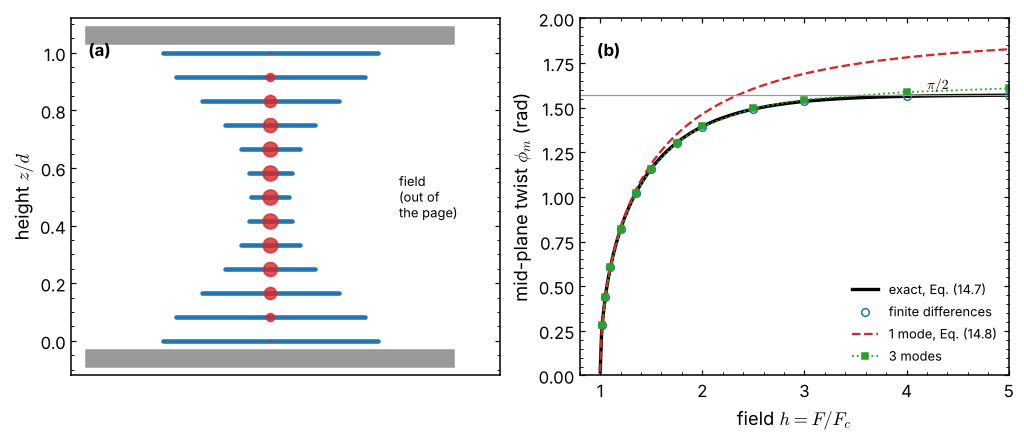

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
h_pic = 2.0
fd_pic = on.director_fd(0.01 * np.sin(np.pi * zz), np.array([0.0, 400.0]), lambda p: h_pic**2 * np.sin(p) * np.cos(p), 1 / np.pi**2)[-1]
levels = np.linspace(0, 1, 13)
twist = np.interp(levels, np.r_[0, zz, 1], np.r_[0, fd_pic, 0])
for zl, p in zip(levels, twist):
    ax1.plot([-0.35 * np.cos(p), 0.35 * np.cos(p)], [zl, zl], color="C0", lw=3, solid_capstyle="round")
    ax1.plot(0, zl, "o", color="C3", ms=1 + 9 * np.sin(p), alpha=0.8)
for zp in (-0.06, 1.06):
    ax1.fill_between([-0.6, 0.6], zp - 0.03, zp + 0.03, color="0.6")
ax1.text(0.42, 0.5, "field\n(out of\nthe page)", fontsize=8.5, va="center")
ax1.set_xlim(-0.65, 0.75); ax1.set_ylim(-0.12, 1.12); ax1.set_xticks([])
ax1.set_ylabel("height $z/d$"); on.panel_label(ax1, "(a)", x=0.04, y=0.94)

hh = np.linspace(1.0001, 5, 300)
ax2.plot(hh, [on.freedericksz_twist_angle(h) for h in hh], "k-", lw=2.2, label="exact, Eq. (14.7)")
ax2.plot(fields, [steady[h][1] for h in fields], "C0o", mfc="none", ms=5, label="finite differences")
ax2.plot(hh, [one_mode_steady(h) for h in hh], "C3--", lw=1.5, label="1 mode, Eq. (14.8)")
ax2.plot(fields, [steady[h][3] for h in fields], "C2s:", ms=4, lw=1.2, label="3 modes")
ax2.axhline(np.pi / 2, color="0.6", lw=0.8)
ax2.text(4.2, np.pi / 2 + 0.03, r"$\pi/2$", fontsize=9)
ax2.set_xlabel(r"field $h = F/F_c$"); ax2.set_ylabel(r"mid-plane twist $\phi_m$ (rad)"); ax2.set_xlim(0.8, 5); ax2.set_ylim(0, 2)
ax2.legend(loc="lower right", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.04, y=0.94)
plt.show()

**Figure 14.1.** **(a)** The director across a twist cell at $h = 2$, seen from the side: the
bars show the component along the anchoring direction, the dots the component
along the field, which points out of the page. **(b)** The twist at the mid-plane against
the field: the exact solution (line), the finite-difference solution (circles), and
trial functions with one and three odd modes.

The finite-difference solution agrees with the exact twist (14.7) to $2\times10^{-5}$ at all
fields. The one-mode trial is excellent near the threshold, within 0.001 at $h = 1.05$, and
poor at strong fields: 0.07 too large at $h = 2$, and beyond $h = 2.35$ its mid-plane twist
exceeds $\pi/2$, which the real director can never do (it would then have turned past
the field). As $h \to \infty$ the trial tends to $a = 1.92$, the zero of $J_1(2a)$, not to $\pi/2$.

The reason is a length that the trial does not contain. The field and the elastic
torque balance over the *field coherence length* $\xi = (K_2/\chi)^{1/2}/F = d/\pi h$. At strong fields
the director lies along the field everywhere except in layers of thickness $\xi$ at the
walls, and a single sine cannot be flat in the middle and steep at the walls. With more
modes the trial converges (three modes are within $2\times10^{-3}$ at $h = 2$), but more slowly
the thinner the wall layers.

## 14.4 Switching on and off

The cell below follows the twist after the field is switched on, from a small initial
twist, and after it is switched off, from the steady state. It compares the
finite-difference solution with the trials and measures the rise time (10 % to 90 % of
the final mid-plane twist) and the fall time (90 % to 10 %).

In [5]:
t_on = np.linspace(0, 12, 1201)
switch_on = {}
for h in (1.2, 2.0, 4.0):
    fd = on.director_fd(0.01 * np.sin(np.pi * zz), t_on, lambda p, h=h: h * h * np.sin(p) * np.cos(p), 1 / np.pi**2)[:, n // 2]
    a1 = ritz_twist(h, 1, t_on)[0][:, 0]
    a3, _, S3 = ritz_twist(h, 3, t_on)
    switch_on[h] = (fd, a1, a3 @ np.sin(np.array([1, 3, 5]) * np.pi / 2))

def crossing(t, y, level):
    i = np.argmax(y >= level) if y[-1] > y[0] else np.argmax(y <= level)
    return np.interp(level, [y[i - 1], y[i]], [t[i - 1], t[i]]) if y[-1] > y[0] else np.interp(level, [y[i], y[i - 1]], [t[i], t[i - 1]])

h_scan = np.array([1.1, 1.2, 1.35, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0])
rise, fall = [], []
t_long = np.linspace(0, 80, 8001)
t_off = np.linspace(0, 6, 1201)
for h in h_scan:
    fd = on.director_fd(0.01 * np.sin(np.pi * zz), t_long, lambda p, h=h: h * h * np.sin(p) * np.cos(p), 1 / np.pi**2)
    mid = fd[:, n // 2]
    rise.append(crossing(t_long, mid, 0.9 * mid[-1]) - crossing(t_long, mid, 0.1 * mid[-1]))
    off = on.director_fd(fd[-1], t_off, lambda p: 0 * p, 1 / np.pi**2)[:, n // 2]
    fall.append(crossing(t_off, off, 0.1 * off[0]) - crossing(t_off, off, 0.9 * off[0]))
rise, fall = np.array(rise), np.array(fall)
print("    h    rise time   (h^2 - 1) x rise    fall time    (units tau_0)")
for h, r, f in zip(h_scan, rise, fall):
    print(f"  {h:4.2f}    {r:7.3f}        {r * (h * h - 1):6.3f}           {f:6.3f}")

    h    rise time   (h^2 - 1) x rise    fall time    (units tau_0)
  1.10     14.678         3.082            2.201
  1.20      7.133         3.138            2.204
  1.35      3.909         3.215            2.208
  1.50      2.628         3.285            2.212
  2.00      1.155         3.464            2.220
  2.50      0.682         3.579            2.224
  3.00      0.455         3.643            2.226
  4.00      0.246         3.691            2.225
  5.00      0.154         3.702            2.224


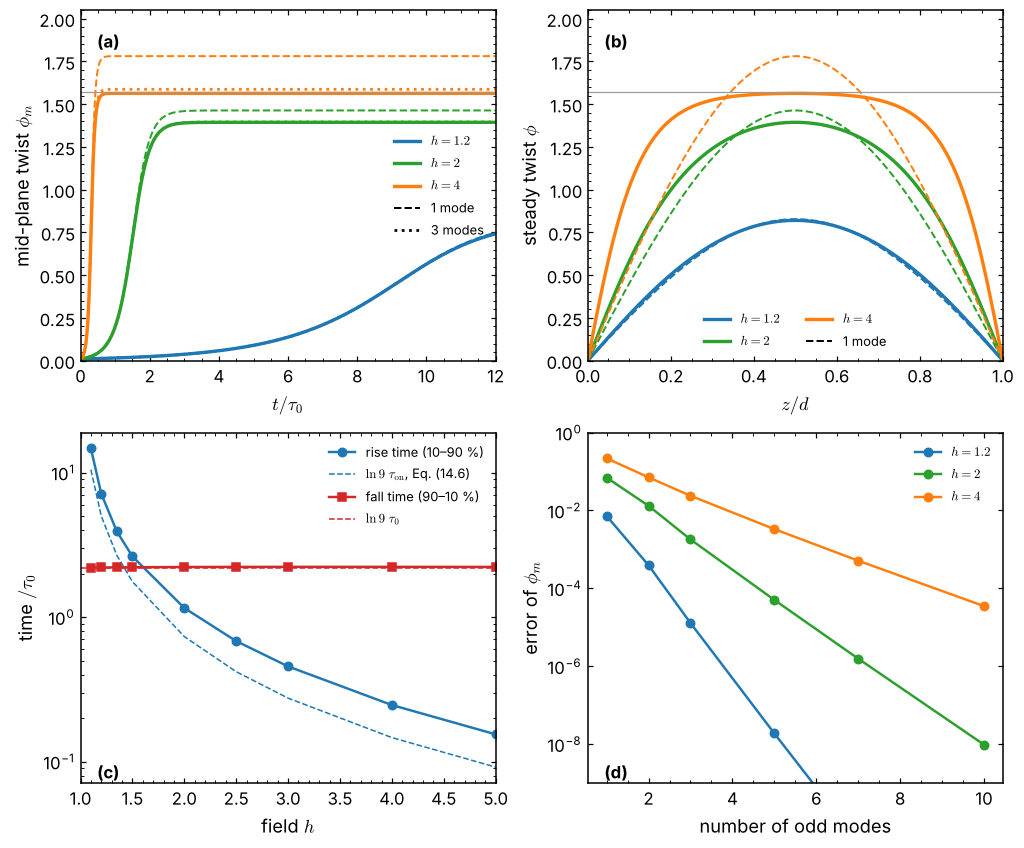

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
ax = axes[0, 0]
for (h, (fd, a1, a3)), color in zip(switch_on.items(), ("C0", "C2", "C1")):
    ax.plot(t_on, fd, color=color, lw=2.2, label=f"$h = {h:g}$")
    ax.plot(t_on, a1, "--", color=color, lw=1.3)
    ax.plot(t_on, a3, ":", color=color, lw=1.8)
ax.plot([], [], "k--", lw=1.3, label="1 mode"); ax.plot([], [], "k:", lw=1.8, label="3 modes")
ax.axhline(np.pi / 2, color="0.6", lw=0.8)
ax.set_xlabel(r"$t/\tau_0$"); ax.set_ylabel(r"mid-plane twist $\phi_m$"); ax.set_xlim(0, 12); ax.set_ylim(0, 2.05)
ax.legend(loc="center right", fontsize=8.5); on.panel_label(ax, "(a)", x=0.04, y=0.94)

ax = axes[0, 1]
zf = np.r_[0, zz, 1]
for h, color in zip((1.2, 2.0, 4.0), ("C0", "C2", "C1")):
    fd = on.director_fd(0.01 * np.sin(np.pi * zz), np.array([0.0, 400.0]), lambda p, h=h: h * h * np.sin(p) * np.cos(p), 1 / np.pi**2)[-1]
    ax.plot(zf, np.r_[0, fd, 0], color=color, lw=2.2, label=f"$h = {h:g}$")
    ax.plot(zf, one_mode_steady(h) * np.sin(np.pi * zf), "--", color=color, lw=1.3)
ax.plot([], [], "k--", lw=1.3, label="1 mode")
ax.axhline(np.pi / 2, color="0.6", lw=0.8)
ax.set_xlabel("$z/d$"); ax.set_ylabel(r"steady twist $\phi$"); ax.set_xlim(0, 1); ax.set_ylim(0, 2.05)
ax.legend(loc="lower center", fontsize=8.5, ncol=2); on.panel_label(ax, "(b)", x=0.04, y=0.94)

ax = axes[1, 0]
ax.semilogy(h_scan, rise, "C0o-", label="rise time (10–90 %)")
ax.semilogy(h_scan, math.log(9) / (h_scan**2 - 1), "C0--", lw=1, label=r"$\ln 9\;\tau_{\rm on}$, Eq. (14.6)")
ax.semilogy(h_scan, fall, "C3s-", label="fall time (90–10 %)")
ax.axhline(math.log(9), color="C3", ls="--", lw=1, label=r"$\ln 9\;\tau_0$")
ax.set_xlabel(r"field $h$"); ax.set_ylabel(r"time $/\tau_0$"); ax.set_xlim(1, 5)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(c)", x=0.04, y=0.06)

ax = axes[1, 1]
for h, color in zip((1.2, 2.0, 4.0), ("C0", "C2", "C1")):
    ms = [1, 2, 3, 5, 7, 10]
    errs = []
    for m in ms:
        a = ritz_twist(h, m, np.array([0.0, 400.0]))[0][-1]
        errs.append(abs(a @ np.sin((2 * np.arange(m) + 1) * np.pi / 2) - on.freedericksz_twist_angle(h)))
    ax.semilogy(ms, errs, "o-", color=color, label=f"$h = {h:g}$")
ax.set_xlabel("number of odd modes"); ax.set_ylabel(r"error of $\phi_m$"); ax.set_ylim(1e-9, 1)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 14.2.** Switching a twist cell. **(a)** The mid-plane twist after the field is
switched on, from a twist of 0.01: finite differences (full lines) and trials with one
mode (dashed) and three modes (dotted). **(b)** Steady profiles: finite differences and the
one-mode trial. **(c)** Rise and fall times against the field, compared with the
estimates of Eq. (14.6) multiplied by $\ln 9$, the factor between 10 % and 90 % of an
exponential. **(d)** Convergence of the trial functions.

The switch-off is the same at every field: the fall time is $2.20$–$2.23\,\tau_0$, close to
$\ln9\,\tau_0 = 2.197\,\tau_0$ for a pure exponential, because without the field the equation is
linear and the slowest mode dominates. The switch-on follows the scaling of
Jakeman and Raynes, $1/(h^2 - 1)$, but takes 40–70 % longer than $\ln9\,\tau_{\rm on}$: the growth is
exponential only at first and slows as the twist saturates. The one-mode trial gets
the timing of the switch-on right at every field and the final twist right only near
the threshold (panel a); the convergence of the trials is geometric, and slower at
strong fields (panel d).

## 14.5 A director in shear flow

Now let the nematic flow. In a simple shear flow $v_x = \dot\gamma z$, with the director in the
plane of the shear, $\mathbf n = (\cos\theta, 0, \sin\theta)$, two things act on the director. The flow
rotates the fluid with the angular velocity $-\dot\gamma/2$, so the rotation of the director
*relative to the fluid* is $N = \dot\theta + \dot\gamma/2$. And the flow stretches the fluid, with the strain
rate $\dot\gamma/2$ along the diagonals, which acts on the director through the component
$\mathbf n\cdot\mathsf A\cdot\mathbf n_\perp = \tfrac12\dot\gamma\cos2\theta$.

*Dissipation.* The dissipation function is a quadratic form in the two rates, $N$ and
$\dot\gamma$:

$$ \Phi = \frac{\gamma_1}{2}N^2 + \gamma_2\,N\,\frac{\dot\gamma}{2}\cos2\theta + \frac{\eta(\theta)}{2}\,\dot\gamma^2 . \tag{14.9} $$

The coupling coefficient $\gamma_2$ appears once in $\Phi$, and therefore twice in the equations:
in the torque that the flow exerts on the director ($\partial\Phi/\partial N$), and in the shear stress that a
rotating director exerts on the fluid ($\partial\Phi/\partial\dot\gamma$). This is Onsager's reciprocity
(Chapter 2). In the theory of Ericksen (1961) and Leslie (1968) the six viscosities
$\alpha_1, \ldots, \alpha_6$ appear separately in the torque and in the stress, and reciprocity is the
relation of Parodi (1970), $\gamma_2 = \alpha_2 + \alpha_3 = \alpha_6 - \alpha_5$, which leaves five independent
viscosities.

*Minimise* over $\dot\theta$ at a given shear rate, adding the elastic torque of a cell (with a
single elastic constant $K$):

$$ \gamma_1\frac{\partial\theta}{\partial t} = K\frac{\partial^2\theta}{\partial z^2} - \frac{\dot\gamma}{2}\big(\gamma_1 + \gamma_2\cos2\theta\big) . \tag{14.10} $$

*A free director.* Without walls, $\dot\theta = -\tfrac12\dot\gamma(1 - \lambda\cos2\theta)$ with $\lambda = -\gamma_2/\gamma_1$. If $\lambda > 1$, as for
most nematics of rod-like molecules, the director stops at the *flow-alignment* (Leslie)
angle

$$ \cos2\theta_L = \frac1\lambda , \tag{14.11} $$

a little above the flow direction. If $\lambda < 1$ it never stops: it *tumbles*, turning by $\pi$ in
the time $2\pi/\dot\gamma(1 - \lambda^2)^{1/2}$.

*A cell.* Between plates that anchor the director along the flow, $\theta = 0$ at $z = 0$ and
$z = d$, the flow and the walls compete. In units of $d$ and $\gamma_1d^2/K$, Eq. (14.10) reads
$\theta_t = \theta_{zz} - \tfrac12\mathrm{Er}\,(1 - \lambda\cos2\theta)$, with the *Ericksen number* $\mathrm{Er} = \gamma_1\dot\gamma d^2/K$, the ratio of viscous
to elastic torques. For small $\mathrm{Er}$ the twist is weak and the mid-plane angle is
$\mathrm{Er}(\lambda - 1)/16$. For large $\mathrm{Er}$ the director aligns at $\theta_L$ in the middle of the cell and
returns to zero in thin layers at the walls. In a layer the first integral of the
steady equation gives

$$ \frac{\partial\theta}{\partial z} = \Big\{\mathrm{Er}\big[g(\theta) - g(\theta_L)\big]\Big\}^{1/2} , \qquad g(\theta) = \theta - \frac\lambda2\sin2\theta , \tag{14.12} $$

so the layers have the thickness $d/\mathrm{Er}^{1/2}$. We take $\lambda = 1.1$ ($\theta_L = 12.3°$) and treat the shear
rate as given. (In a real cell the director also changes the local viscosity, and with it
the shear rate across the gap; including this needs the velocity as a second slow
variable, with the shear stress as the Lagrange multiplier of the imposed plate
speed.)

In [7]:
lam_align, lam_tumble = 1.1, 0.9
theta_L = 0.5 * math.acos(1 / lam_align)
print(f"lambda = {lam_align}: Leslie angle {theta_L:.5f} rad = {math.degrees(theta_L):.2f} deg")
print(f"lambda = {lam_tumble}: tumbling period {2 * math.pi / math.sqrt(1 - lam_tumble**2):.3f} / shear rate")

free = {}
t_free = np.linspace(0, 40, 2001)
for lam in (lam_align, lam_tumble):
    sol = solve_ivp(lambda t, th: [-0.5 * (1 - lam * np.cos(2 * th[0]))], (0, 40), [0.0], t_eval=t_free, rtol=1e-11, atol=1e-12)
    free[lam] = sol.y[0]
crossings = t_free[1:][np.diff(np.floor(-free[lam_tumble] / np.pi)) > 0]
print(f"tumbling: the director turns by pi every {np.diff(crossings).mean():.3f} (numerical)")

def g(th):
    return th - lam_align / 2 * np.sin(2 * th)

def cell_trial(Er):
    """One-mode trial theta = a sin(pi z) for the sheared cell: pi^2 a = Er [lambda I(a) - 2/pi]."""
    I = lambda a: quad(lambda s: math.cos(2 * a * math.sin(math.pi * s)) * math.sin(math.pi * s), 0, 1)[0]
    return brentq(lambda a: math.pi**2 * a - Er * (lam_align * I(a) - 2 / math.pi), 0.0, 1.5)

n_c = 1199
zc = np.arange(1, n_c + 1) / (n_c + 1)
ericksen = np.array([0.3, 1, 3, 10, 30, 100, 300, 1000, 3000, 1e4])
mid_fd, profiles_fd = [], {}
for Er in ericksen:
    prof = on.director_fd(np.zeros(n_c), np.array([0.0, 3.0]), lambda th, Er=Er: -0.5 * Er * (1 - lam_align * np.cos(2 * th)))[-1]
    mid_fd.append(prof[n_c // 2])
    profiles_fd[Er] = prof
mid_fd = np.array(mid_fd)
mid_trial = np.array([cell_trial(Er) for Er in ericksen])
print("\n     Er      mid-plane angle: finite diff.   small Er    one-mode trial   (theta_L = %.5f)" % theta_L)
for Er, m1, m2 in zip(ericksen, mid_fd, mid_trial):
    print(f"  {Er:7g}        {m1:.5f}            {Er * (lam_align - 1) / 16:9.5f}     {m2:.5f}")
print("\nwall layer, z at which theta = theta_L/2:   finite diff.   Eq. (14.12)")
for Er in (100, 1000, 1e4):
    prof = profiles_fd[Er]
    z_half = np.interp(theta_L / 2, prof[: n_c // 2], zc[: n_c // 2])
    z_theory = quad(lambda th: 1 / math.sqrt(Er * (g(th) - g(theta_L))), 0, theta_L / 2)[0]
    print(f"   Er = {Er:6g}:                   {z_half:.5f}      {z_theory:.5f}")

lambda = 1.1: Leslie angle 0.21485 rad = 12.31 deg
lambda = 0.9: tumbling period 14.415 / shear rate
tumbling: the director turns by pi every 14.420 (numerical)



     Er      mid-plane angle: finite diff.   small Er    one-mode trial   (theta_L = 0.21485)
      0.3        0.00187              0.00188     0.00193
        1        0.00625              0.00625     0.00645
        3        0.01864              0.01875     0.01925
       10        0.05898              0.06250     0.06099
       30        0.13297              0.18750     0.13898
      100        0.19715              0.62500     0.21461
      300        0.21338              1.87500     0.24594
     1000        0.21484              6.25000     0.25812
     3000        0.21485             18.75000     0.26173
    10000        0.21485             62.50000     0.26300

wall layer, z at which theta = theta_L/2:   finite diff.   Eq. (14.12)
   Er =    100:                   0.11813      0.11705
   Er =   1000:                   0.03702      0.03702
   Er =  10000:                   0.01171      0.01171


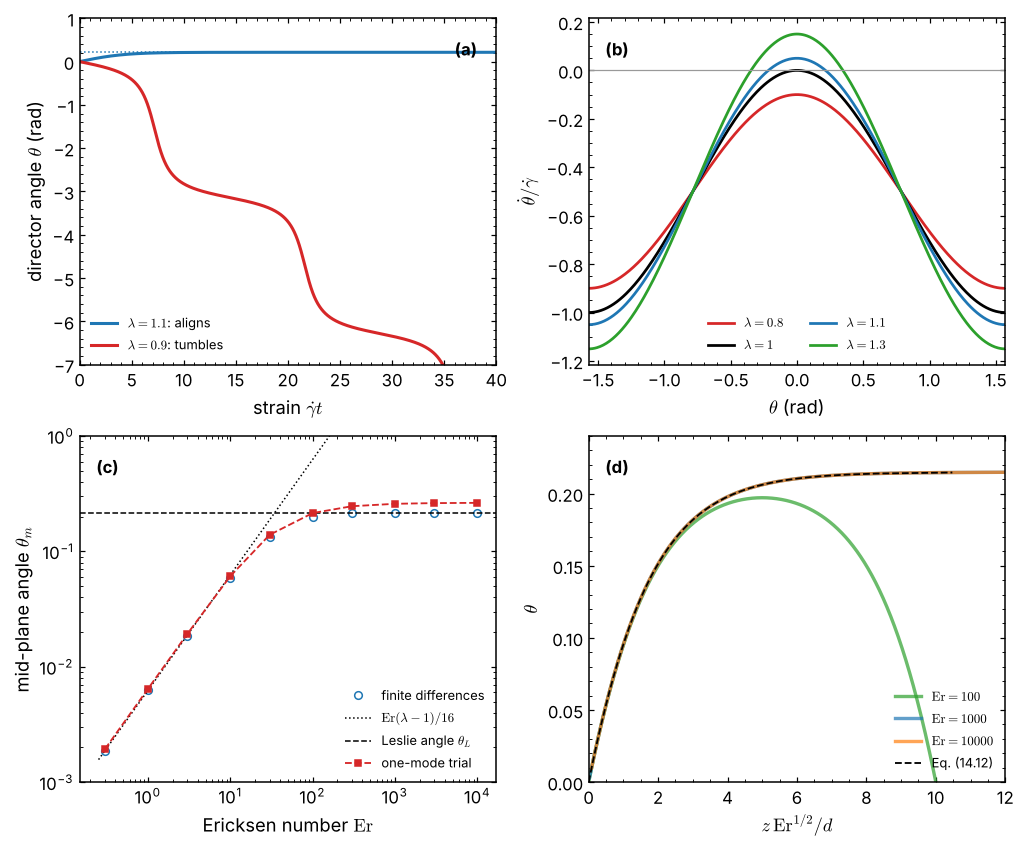

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
ax = axes[0, 0]
ax.plot(t_free, free[lam_align], "C0", lw=2, label=rf"$\lambda = {lam_align}$: aligns")
ax.plot(t_free, free[lam_tumble], "C3", lw=2, label=rf"$\lambda = {lam_tumble}$: tumbles")
ax.axhline(theta_L, color="C0", ls=":", lw=1)
ax.set_xlabel(r"strain $\dot\gamma t$"); ax.set_ylabel(r"director angle $\theta$ (rad)"); ax.set_xlim(0, 40); ax.set_ylim(-7, 1)
ax.legend(loc="lower left", fontsize=8.5); on.panel_label(ax, "(a)", x=0.9, y=0.94)

ax = axes[0, 1]
th = np.linspace(-np.pi / 2, np.pi / 2, 400)
for lam, color in zip((0.8, 1.0, 1.1, 1.3), ("C3", "k", "C0", "C2")):
    ax.plot(th, -0.5 * (1 - lam * np.cos(2 * th)), color=color, lw=1.8, label=rf"$\lambda = {lam:g}$")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel(r"$\theta$ (rad)"); ax.set_ylabel(r"$\dot\theta/\dot\gamma$"); ax.set_xlim(-np.pi / 2, np.pi / 2)
ax.legend(loc="lower center", fontsize=8.5, ncol=2); on.panel_label(ax, "(b)", x=0.04, y=0.94)

ax = axes[1, 0]
Er_line = np.logspace(-0.6, 4, 200)
ax.loglog(ericksen, mid_fd, "C0o", mfc="none", ms=5, label="finite differences")
ax.loglog(Er_line, Er_line * (lam_align - 1) / 16, "k:", lw=1, label=r"$\mathrm{Er}(\lambda - 1)/16$")
ax.axhline(theta_L, color="k", ls="--", lw=1, label=r"Leslie angle $\theta_L$")
ax.loglog(ericksen, mid_trial, "C3s--", ms=4, lw=1.2, label="one-mode trial")
ax.set_xlabel(r"Ericksen number $\mathrm{Er}$"); ax.set_ylabel(r"mid-plane angle $\theta_m$"); ax.set_ylim(1e-3, 1)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(c)", x=0.04, y=0.94)

ax = axes[1, 1]
for Er, color in zip((100, 1000, 1e4), ("C2", "C0", "C1")):
    prof = profiles_fd[Er]
    ax.plot(zc * math.sqrt(Er), prof, color=color, lw=2.2, alpha=0.7, label=rf"$\mathrm{{Er}} = {Er:g}$")
ths = np.linspace(1e-4, theta_L * (1 - 1e-3), 300)
zs = [quad(lambda s: 1 / math.sqrt(g(s) - g(theta_L)), 0, x, limit=200)[0] for x in ths]
ax.plot(zs, ths, "k--", lw=1.2, label="Eq. (14.12)")
ax.set_xlabel(r"$z\,\mathrm{Er}^{1/2}/d$"); ax.set_ylabel(r"$\theta$"); ax.set_xlim(0, 12); ax.set_ylim(0, 0.24)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 14.3.** A nematic in shear flow. **(a)** A free director, started along the flow:
for $\lambda > 1$ it stops at the Leslie angle (dotted), for $\lambda < 1$ it tumbles. **(b)** The rate of
rotation against the angle: zeros exist only for $\lambda \ge 1$. **(c)** The mid-plane angle in a
sheared cell against the Ericksen number, $\lambda = 1.1$. **(d)** The wall layers collapse when
distance is scaled with $d/\mathrm{Er}^{1/2}$ and follow the exact layer profile.

The free director tumbles with the predicted period (14.42 against 14.415 per unit
shear rate, the difference being the time sampling). In the cell, the mid-plane
angle follows $\mathrm{Er}(\lambda - 1)/16$ up to $\mathrm{Er} \approx 3$ and reaches the Leslie angle, to five digits, for
$\mathrm{Er} \gtrsim 1000$. The wall layers agree with the exact layer profile (14.12) to four digits for
$\mathrm{Er} \ge 1000$, and within 1 % already at $\mathrm{Er} = 100$.

The one-mode trial $\theta = a\sin\pi z$ repeats the story of the twist cell: it is right for weak flow
and wrong for strong flow, where it gives a mid-plane angle 22 % above the Leslie
angle. Again the trial lacks a length, here the layer thickness $d/\mathrm{Er}^{1/2}$. Wall layers whose
thickness shrinks with a control parameter are the common situation in which a few
smooth trial functions fail, in this chapter as in Chapters 10 and 12.

## 14.6 What to trust

* The director theory assumes a nematic of uniform order. Near defects, at very
  strong distortions or close to the transition to the isotropic liquid, the degree of
  order changes too, and a tensor order parameter is needed.
* The twist cell needs no flow. In splay and bend geometries the rotating director
  drives a flow (backflow), which changes the switching dynamics; the shear-flow
  section shows how the velocity enters the Rayleighian.
* The anchoring at the walls was taken as infinitely strong. With a finite anchoring
  energy the threshold falls (Exercise 4).
* An electric field inside a distorted nematic is not uniform, because the dielectric
  constant depends on the director; a magnetic field is. For the twist cell with an
  in-plane field this effect was ignored.

## Summary

* The director has the Frank elastic energy, the energy of a field, and the dissipation
  of rotational friction. The Rayleighian gives the torque balance of Eq. (14.3).
* A field turns the director only above the Fréedericksz threshold $F_c = (\pi/d)(K_2/\chi)^{1/2}$.
  Above it the twist grows as $2(F/F_c - 1)^{1/2}$; the exact steady state is given by an
  elliptic integral.
* A trial with one Fourier mode gives the exact threshold behaviour, but at strong
  fields it overshoots the maximum twist of $\pi/2$; a few odd modes are needed.
* In shear flow the dissipation function couples the rotation of the director to the
  shear rate. Reciprocity of this coupling is the Parodi relation. The director aligns
  at the Leslie angle if $\lambda > 1$ and tumbles if $\lambda < 1$; in a cell it forms wall layers of
  thickness $d/\mathrm{Er}^{1/2}$.

## Exercises

Sample solutions are in [`solutions/part3_soft_materials/14_solutions.ipynb`](../../solutions/part3_soft_materials/14_solutions.ipynb).

1. **A display cell.** Take $K_2 = 3$ pN, $\gamma_1 = 0.1$ Pa s, $\Delta\varepsilon = 10$ and $d = 4$ µm, typical orders of
   magnitude. Find the threshold field $E_c$, the switch-off time $\tau_0$, and the field needed
   for the switch-on time $\tau_{\rm on}$ to equal 1 ms.
2. **Beyond the threshold.** Expand Eq. (14.7) to show that $h - 1 = \tfrac14\phi_m^2 + \tfrac{11}{192}\phi_m^4 + \ldots$ and
   Eq. (14.8) to show that the one-mode trial gives $h - 1 = \tfrac14a^2 + \tfrac{5}{96}a^4 + \ldots$ What does the
   difference mean? Check both expansions numerically.
3. **Switching off.** Without field, Eq. (14.5) is linear. Starting from the steady state at
   $h = 4$, write the solution as a sum of modes and compare the decay of the mid-plane twist
   with $e^{-t/\tau_0}$. Why does it start so slowly? Why is the fall time almost independent of
   the field?
4. **Weak anchoring.** Add an anchoring energy $\tfrac12W\sin^2\phi$ per unit area at each plate to
   Eq. (14.1). Show from the Rayleighian that the boundary condition becomes
   $K_2\phi' = W\phi$ at $z = 0$ (for small $\phi$), and that the threshold wave number $q_c$ obeys
   $\tfrac12q_cd\,\tan(\tfrac12q_cd) = d/2b$, with the extrapolation length $b = K_2/W$. How much does the
   threshold field fall for $b = d/10$?

## Suggested references

* P. G. de Gennes and J. Prost, *The Physics of Liquid Crystals*, 2nd ed. (Oxford University Press, 1993).
* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* V. Fréedericksz and V. Zolina, "Forces causing the orientation of an anisotropic liquid", *Trans. Faraday Soc.* **29**, 919 (1933).
* F. C. Frank, "On the theory of liquid crystals", *Discuss. Faraday Soc.* **25**, 19 (1958).
* J. L. Ericksen, "Conservation laws for liquid crystals", *Trans. Soc. Rheol.* **5**, 23 (1961).
* F. M. Leslie, "Some constitutive equations for liquid crystals", *Arch. Ration. Mech. Anal.* **28**, 265 (1968).
* O. Parodi, "Stress tensor for a nematic liquid crystal", *J. Phys. (Paris)* **31**, 581 (1970).
* E. Jakeman and E. P. Raynes, "Electro-optic response times in liquid crystals", *Phys. Lett. A* **39**, 69 (1972).

---

**Previous:** [13. Polymer dynamics](13_polymer_dynamics.ipynb)